In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns


In [2]:
df = pd.read_csv("../Task_1_Data_Cleaning/netflix_cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
df["country"].head(10)

0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: object

In [4]:
country_df = df.assign(
    country=df["country"].str.split(", ")
).explode("country")

country_df["country"] = country_df["country"].str.strip()

country_df.head(10)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
5,s9,TV Show,The Great British Baking Show,Andy Devonshire,United Kingdom,9/24/2021,2021,TV-14,9 Seasons,"British TV Shows, Reality TV"
6,s10,Movie,The Starling,Theodore Melfi,United States,9/24/2021,2021,PG-13,104 min,"Comedies, Dramas"
7,s939,Movie,Motu Patlu in the Game of Zones,Suhas Kadav,India,5/1/2021,2019,TV-Y7,87 min,"Children & Family Movies, Comedies, Music & Mu..."
8,s13,Movie,Je Suis Karl,Christian Schwochow,Germany,9/23/2021,2021,TV-MA,127 min,"Dramas, International Movies"
9,s940,Movie,Motu Patlu in Wonderland,Suhas Kadav,India,5/1/2021,2013,TV-Y7,76 min,"Children & Family Movies, Music & Musicals"


In [5]:
country_counts = country_df["country"].value_counts()

country_counts.head(20)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             112
Nigeria            105
Germany            104
China              100
Brazil              88
Taiwan              86
Indonesia           86
Name: count, dtype: int64

In [6]:
top_10_countries = country_counts.head(10)

top_10_countries

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

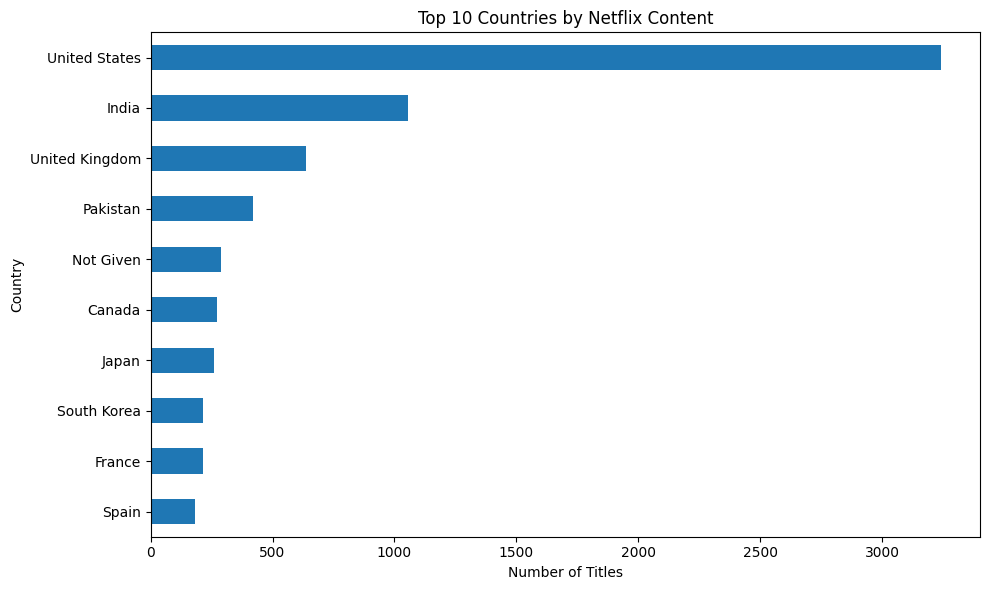

In [7]:
plt.figure(figsize=(10, 6))

top_10_countries.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [10]:
country_type = pd.crosstab(
    country_df["country"],
    country_df["type"]
)

country_type.head(10)

type,Movie,TV Show
country,,
Argentina,56,20
Australia,61,53
Austria,8,1
Bangladesh,3,0
Belarus,0,1
Belgium,9,9
Brazil,60,28
Bulgaria,5,0
Cambodia,2,0


In [11]:
top_countries = country_counts.head(10).index

country_type_top10 = country_type.loc[top_countries]

country_type_top10

type,Movie,TV Show
country,,
United States,2395,845
India,976,81
United Kingdom,387,251
Pakistan,71,350
Not Given,257,30
Canada,187,84
Japan,87,172
South Korea,49,165
France,148,65


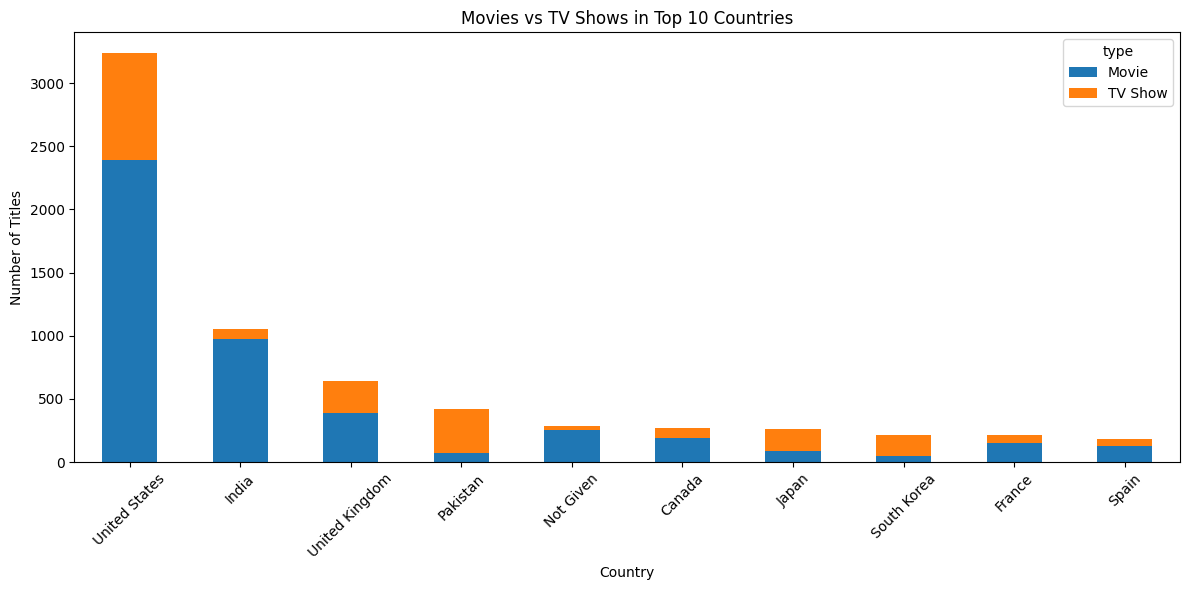

In [13]:
country_type_top10.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows in Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [14]:
print("KEY FINDINGS")
print("----------------------------")

print("Top 10 countries by Netflix content:")
print(top_10_countries)

print("\nTotal unique countries:")
print(country_df["country"].nunique())

print("\nCountry with the highest number of titles:")
print(country_counts.idxmax())

print("\nHighest number of titles:")
print(country_counts.max())

KEY FINDINGS
----------------------------
Top 10 countries by Netflix content:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

Total unique countries:
86

Country with the highest number of titles:
United States

Highest number of titles:
3240


# Task 3 — Country-Wise Netflix Content Analysis

## Key Findings

- The **United States** has the highest number of titles with **3,240**.
- **India** ranks second with **1,057** titles.
- The **United Kingdom** ranks third with **638** titles.
- Pakistan, Canada, Japan, South Korea, France, and Spain are also among the top content-producing countries.
- The country-wise analysis also compares Movies and TV Shows across the top countries.

## Conclusion

The analysis shows that Netflix content is distributed across many countries, with the United States contributing the largest number of titles. The country-wise comparison provides useful insights into Netflix's global content distribution.